In [66]:
!pip install pandas numpy seaborn

In [2]:
import pandas as pd

In [31]:
pd.set_option('display.float_format', lambda x: f'{x:.15g}')

df = pd.read_csv('data/star_classification.csv')

# converting ID columns to string
id_cols = ['obj_ID', 'spec_obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'plate', 'fiber_ID']

df = pd.read_csv('data/star_classification.csv', dtype={c: str for c in id_cols})

# convert MJD to standard datetime
df['Date'] = pd.to_datetime(df['MJD'], unit='D', origin='1858-11-17')

# Dropped 1 row with -9999 value in u/g/z. The same row has this value for all three columns. 
# Placeholder, not a real measurement; 0.001% of data.
df = df[df['u'] != -9999]

print(df.shape)
print()
print('Columns:',df.columns.tolist())
print()
print('Data types')
print(df.dtypes)
print()

df.head()

(99999, 19)

Columns: ['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID', 'Date']

Data types
obj_ID                   str
alpha                float64
delta                float64
u                    float64
g                    float64
r                    float64
i                    float64
z                    float64
run_ID                   str
rerun_ID                 str
cam_col                  str
field_ID                 str
spec_obj_ID              str
class                    str
redshift             float64
plate                    str
MJD                    int64
fiber_ID                 str
Date           datetime64[s]
dtype: object



,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID,Date
0,1237660961327743232,135.6891066036,32.4946318397087,23.87882,22.2753,20.39501,19.16573,18.79371,3606,301,2,79,6543777369295181824,GALAXY,0.6347936,5812,56354,171,2013-03-03
1,1237664879951151360,144.826100550256,31.2741848944939,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,11760142036707334144,GALAXY,0.779136,10445,58158,427,2018-02-09
2,1237660961330430208,142.188789562506,35.5824441819976,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5152200256025548800,GALAXY,0.6441945,4576,55592,299,2011-01-31
3,1237663478724297984,338.741037753146,-0.402827574587482,22.13682,23.77656,21.61162,20.50454,19.2501,4192,301,3,214,10301071412954421248,GALAXY,0.9323456,9149,58039,775,2017-10-13
4,1237680272041378048,345.282593210935,21.1838656010284,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6891864880783316992,GALAXY,0.1161227,6121,56187,842,2012-09-17


### EDA

In [6]:
# spec_obj_ID is the ID for one spectrum.
# are there duplicates?
counts = df['spec_obj_ID'].value_counts()
dup_counts = counts[counts > 1]
print(dup_counts)

Series([], Name: count, dtype: int64)


In [8]:
# check for missing values
df.isna().sum()
# no null values in the dataset

obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64

In [21]:
df.describe()

,obj_ID,alpha,delta,u,g,r,i,z,redshift,plate,MJD,Date
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000
mean,1.2376647218149e+18,177.629116621636,24.1353045953523,21.980468269,20.5313869616,19.645762146,19.08485423203,18.66881032223,0.5766608040203,5137.00966,55588.6475,2011-01-27 15:32:24
min,1.23764594290439e+18,0.0055278279239701,-18.7853280771825,-9999,-9999,9.82207,9.469903,-9999,-0.009970667,266,51608,2000-03-05 00:00:00
25%,1.23765916119512e+18,127.518221542123,5.14677085793723,20.3523525,18.96523,18.1358275,17.732285,17.4606775,0.054516845,2526,54234,2007-05-14 00:00:00
50%,1.23766346314429e+18,180.900700120969,23.6459222983584,22.179135,21.099835,20.12529,19.405145,19.004595,0.42417325,4987,55868.5,2011-11-03 12:00:00
75%,1.23766835028645e+18,233.895004945922,39.9015500976459,23.68744,22.1237675,21.044785,20.396495,19.92112,0.704154325,7400.25,56777,2014-04-30 00:00:00
max,1.23768053135639e+18,359.999809770956,83.00051858898,32.78139,31.60224,29.57186,32.14147,29.38374,7.011245,12547,58932,2020-03-24 00:00:00
std,8438559894562.57,96.502240898332,19.6446654042937,31.7692908037504,31.7502923290832,1.85475969434553,1.75789479049039,31.7281517859536,0.730707276188809,2952.30335133053,1808.48423285246,NaN


In [22]:
# u, g, z
df[df['u'] < 0].head()

# -9999 is a placeholder for no measurement.

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID,Date
79543,1.2376487035211e+18,224.00652611366,-0.624303881323656,-9999,-9999,18.1656,18.01675,-9999,752,301,2,537,3.7312769048802514e+18,STAR,8.934163e-05,3314,54970,162,2009-05-19


In [34]:
# alpha - range 0 to 360; like longitude, wrapping around the full circle. 
# delta - range -90 to 90; like latitude, from the south pole of the sky to the north pole.

alpha_outside_count = (~df['alpha'].between(0, 360)).sum()
delta_outside_count = (~df['delta'].between(-90, 90)).sum()
print(alpha_outside_count, delta_outside_count)

# in the data:
# alpha: min ~0, max ~360
# delta: min ~18, max ~83

0 0


In [29]:
# redshift range by class
df.groupby('class')['redshift'].describe()

# STAR - redshift around 0
# GALAXY - redshift between 0 and 2
# QSO - redshift between 0 and 7
# GALAXY AND QSO overlap

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
GALAXY,59445,0.421596150444753,0.264857605858102,-0.009970667,0.1645267,0.4562742,0.5946987,1.995524
QSO,18961,1.71967608929113,0.913954276322147,0.0004606231,1.106605,1.617232,2.220279,7.011245
STAR,21593,-0.000114906661842392,0.000465162870207338,-0.004136078,-0.0002953639,-7.61614e-05,7.541069e-05,0.004153254


In [38]:
# class distribution
round(df['class'].value_counts(normalize=True) * 100, 2)
# Baseline: if the model ignores all inputs and always answers with the dominating class, accuracy will be 59.45%

class
GALAXY   59.45
STAR     21.59
QSO      18.96
Name: proportion, dtype: float64

In [41]:
# Brightness depends on distance but color doesn't, so colors are better.
# The five filter values define how bright the object looks through each of the five filters.
# The values are magnitudes, which work backwards: a smaller number means brighter. 
# The scale is logarithmic, so a difference of 5 magnitudes means 100× brighter. 
# The difference between two filters (e.g. u − g) is called a color and tells you whether the object gives off more blue or more red light.

df['u_g'] = df['u'] - df['g']
df['g_r'] = df['g'] - df['r']
df['r_i'] = df['r'] - df['i']
df['i_z'] = df['i'] - df['z']

filters = ['u', 'g', 'r', 'i', 'z']
colors  = ['u_g', 'g_r', 'r_i', 'i_z']
classes = ['GALAXY', 'STAR', 'QSO']

# Standard deviation is a summary of data dispersion or variability expressed in the same units as your original data.
# A small standard deviation means values cluster tightly around the mean. 
# A large standard deviation indicates data points spread out over a wide range.
df.groupby('class')[filters + colors].agg(['median', 'std']).round(2)

u           g           r           i           z         u_g  \
       median  std median  std median  std median  std median  std median   
class                                                                       
GALAXY  22.84 2.26  21.58 2.11   20.1 1.87  19.22 1.69  18.77 1.66   1.64   
QSO      21.5  1.5  21.06 1.16  20.77 1.08  20.58 1.08  20.37  1.1   0.39   
STAR    21.01 2.36  19.54 2.12  18.96 1.97  18.59 1.84  18.32 1.84   1.32   

               g_r         r_i         i_z       
        std median  std median  std median  std  
class                                            
GALAXY 1.23    1.4 0.63   0.72  0.4   0.39 0.35  
QSO    0.84   0.21 0.45   0.15 0.39   0.16  0.4  
STAR   0.94   0.53 0.66   0.21 0.61   0.12 0.55

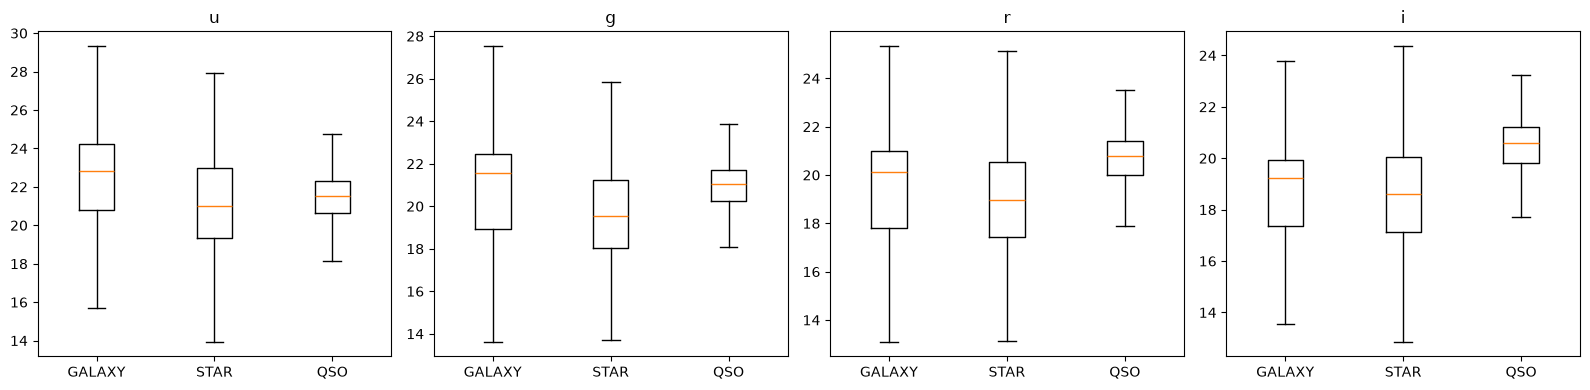

In [43]:
# A boxplot displays the distribution of numerical data and its five-number summary.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, colors):
    ax.boxplot([df.loc[df['class'] == c, col] for c in classes],
               tick_labels=classes, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

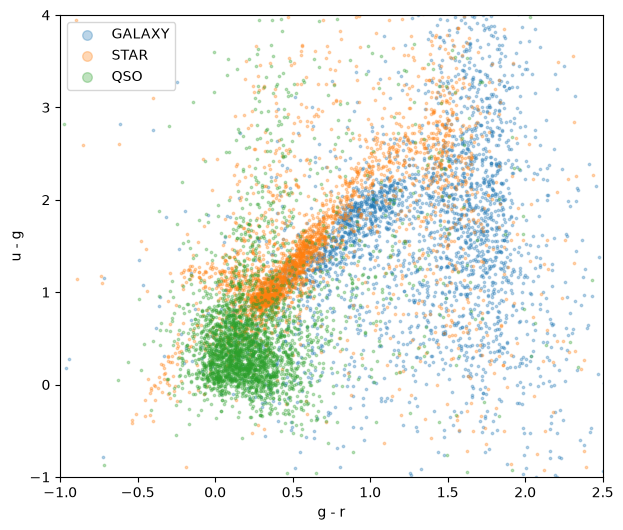

In [72]:
sample = df.groupby('class').sample(n=3000, random_state=42)

fig, ax = plt.subplots(figsize=(7, 6))
for c in classes:
    s = sample[sample['class'] == c]
    ax.scatter(s['g_r'], s['u_g'], s=3, alpha=0.3, label=c)
ax.set_xlabel('g - r')
ax.set_ylabel('u - g')
ax.set_xlim(-1, 2.5)
ax.set_ylim(-1, 4)
ax.legend(markerscale=4)
plt.show()

### Model

In [52]:
# build train and test dataset
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

features = ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z']
X = df[features]
y = df['class']

# Split: 80% train, 20% test, same class proportions in both
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Row labels of each split, reused below so every feature set is scored on the same objects
train_idx = X_train.index
test_idx = X_test.index

In [68]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix


def my_confusion_matrix(y_preds):
    labels = ["GALAXY", "STAR", "QSO"]
    cm_raw = confusion_matrix(y_test, y_preds, labels=labels)

    # 2. Convert to Pandas DataFrame for cleaner axis labeling
    cm_df = pd.DataFrame(cm_raw, index=labels, columns=labels)
    
    # 3. Plot the Heatmap
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm_df,
        annot=True,  # Puts the numbers inside the grid squares
        fmt="d",  # Formats numbers as integers instead of scientific notation
        cmap="Blues",  # Color gradient palette
        cbar=True,  # Shows the color intensity scale bar
        square=True,  # Forces cells to be perfectly square
    )
    
    plt.title("Multiclass Confusion Matrix", fontsize=14, pad=15)
    plt.xlabel("Predicted Class", fontsize=12, labelpad=10)
    plt.ylabel("Actual Class", fontsize=12, labelpad=10)
    plt.tight_layout()
    plt.show()

===== baseline =====
              precision    recall  f1-score   support

      GALAXY       0.59      1.00      0.75     11889
         QSO       0.00      0.00      0.00      3792
        STAR       0.00      0.00      0.00      4319

    accuracy                           0.59     20000
   macro avg       0.20      0.33      0.25     20000
weighted avg       0.35      0.59      0.44     20000



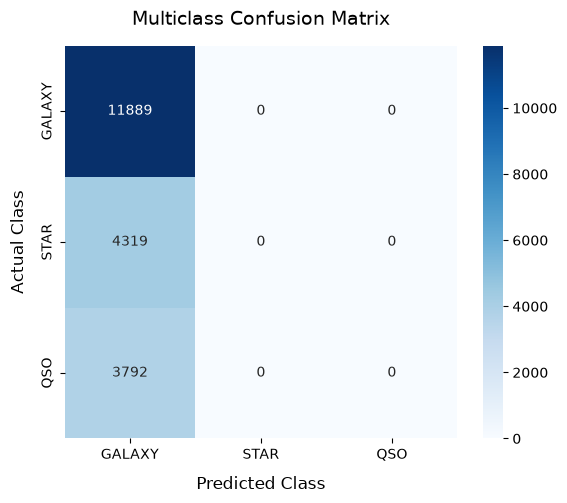

In [69]:
from sklearn.dummy import DummyClassifier

name = "baseline"
model0 = DummyClassifier(strategy="most_frequent")
model0.fit(X_train, y_train)
preds0 = model0.predict(X_test)
print(f'===== {name} =====')
print(classification_report(y_test, preds0, zero_division=0))

my_confusion_matrix(preds0)

===== logreg =====
              precision    recall  f1-score   support

      GALAXY       0.80      0.90      0.85     11889
         QSO       0.67      0.80      0.73      3792
        STAR       0.67      0.32      0.44      4319

    accuracy                           0.76     20000
   macro avg       0.71      0.67      0.67     20000
weighted avg       0.75      0.76      0.74     20000



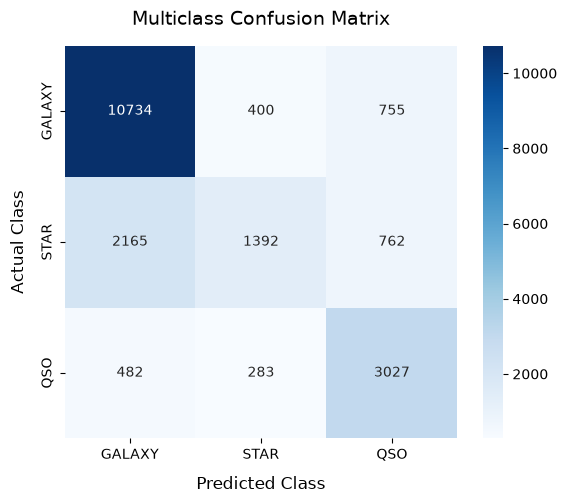

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

name = "logreg"
model1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model1.fit(X_train, y_train)
preds1 = model1.predict(X_test)
print(f'===== {name} =====')
print(classification_report(y_test, preds1, zero_division=0))

my_confusion_matrix(preds1)

===== forest =====
              precision    recall  f1-score   support

      GALAXY       0.92      0.95      0.93     11889
         QSO       0.82      0.80      0.81      3792
        STAR       0.85      0.78      0.81      4319

    accuracy                           0.88     20000
   macro avg       0.86      0.84      0.85     20000
weighted avg       0.88      0.88      0.88     20000



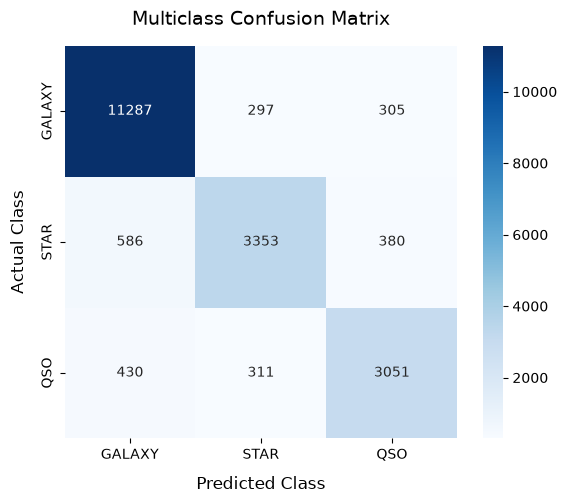

In [71]:
from sklearn.ensemble import RandomForestClassifier

name = "forest"
model2 = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
model2.fit(X_train, y_train)
preds2 = model2.predict(X_test)
print(f'===== {name} =====')
print(classification_report(y_test, preds2, zero_division=0))

my_confusion_matrix(preds2)

In [76]:
position = ['alpha', 'delta']

feature_sets = {
    'colors + r':                     colors + ['r'],
    'raw filters only':               filters,
    'raw filters + alpha/delta':      filters + position,
    'colors only':                    colors,
    'colors + alpha/delta':           colors + position,
    'filters + colors':               filters + colors,
    'filters + colors + alpha/delta': filters + colors + position,
}

In [77]:
# Cross-validation: score each feature set on 5 different train/validation splits of the training data.
# The test set is not touched here; it is kept for one final check of the chosen model.
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Same 5 folds for every feature set; stratified so each fold keeps the class mix
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for name, cols in feature_sets.items():
    model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
    scores = cross_val_score(model, df.loc[train_idx, cols], y_train,
                             cv=cv, scoring='f1_macro')
    print(f'{name:32s} {scores.round(3)}')
    cv_results.append({'feature set': name,
                       'n features': len(cols),
                       'mean macro F1': scores.mean(),
                       'std': scores.std()})

# If two means differ by less than about one std, treat them as tied and prefer the simpler set
pd.DataFrame(cv_results).sort_values('mean macro F1', ascending=False).round(3)

colors + r                       [0.851 0.853 0.851 0.858 0.858]
raw filters only                 [0.836 0.841 0.837 0.84  0.84 ]
raw filters + alpha/delta        [0.838 0.843 0.837 0.839 0.84 ]
colors only                      [0.826 0.831 0.823 0.834 0.83 ]
colors + alpha/delta             [0.844 0.845 0.836 0.842 0.843]
filters + colors                 [0.853 0.854 0.852 0.854 0.857]
filters + colors + alpha/delta   [0.857 0.86  0.857 0.859 0.863]


,feature set,n features,mean macro F1,std
6,filters + colors + alpha/delta,11,0.859,0.002
0,colors + r,5,0.854,0.003
5,filters + colors,9,0.854,0.002
4,colors + alpha/delta,6,0.842,0.003
2,raw filters + alpha/delta,7,0.84,0.002
1,raw filters only,5,0.839,0.002
3,colors only,4,0.829,0.004


In [75]:
# Compare feature sets with the same random forest settings
from sklearn.metrics import f1_score

results = []
for name, cols in feature_sets.items():
    model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
    model.fit(df.loc[train_idx, cols], y_train)
    preds = model.predict(df.loc[test_idx, cols])
    print(f'===== {name} =====')
    print(classification_report(y_test, preds, zero_division=0))
    results.append({'feature set': name,
                    'n features': len(cols),
                    'macro F1': f1_score(y_test, preds, average='macro')})

# Macro F1 score is the average F1 score for that model across all classes, where every class gets an equal vote.
pd.DataFrame(results).sort_values('macro F1', ascending=False).round(3)

===== colors + r =====
              precision    recall  f1-score   support

      GALAXY       0.92      0.95      0.93     11889
         QSO       0.82      0.80      0.81      3792
        STAR       0.85      0.77      0.81      4319

    accuracy                           0.89     20000
   macro avg       0.86      0.84      0.85     20000
weighted avg       0.88      0.89      0.88     20000

===== raw filters only =====
              precision    recall  f1-score   support

      GALAXY       0.91      0.94      0.93     11889
         QSO       0.81      0.79      0.80      3792
        STAR       0.82      0.75      0.78      4319

    accuracy                           0.87     20000
   macro avg       0.85      0.83      0.84     20000
weighted avg       0.87      0.87      0.87     20000

===== raw filters + alpha/delta =====
              precision    recall  f1-score   support

      GALAXY       0.91      0.95      0.93     11889
         QSO       0.81      0.81      

,feature set,n features,macro F1
6,filters + colors + alpha/delta,11,0.86
0,colors + r,5,0.852
5,filters + colors,9,0.851
2,raw filters + alpha/delta,7,0.842
4,colors + alpha/delta,6,0.842
1,raw filters only,5,0.837
3,colors only,4,0.826


===== final model: colors + r =====
              precision    recall  f1-score   support

      GALAXY       0.92      0.95      0.93     11889
         QSO       0.82      0.80      0.81      3792
        STAR       0.85      0.77      0.81      4319

    accuracy                           0.89     20000
   macro avg       0.86      0.84      0.85     20000
weighted avg       0.88      0.89      0.88     20000

Test macro F1: 0.852  (CV estimate: 0.854 ± 0.003)


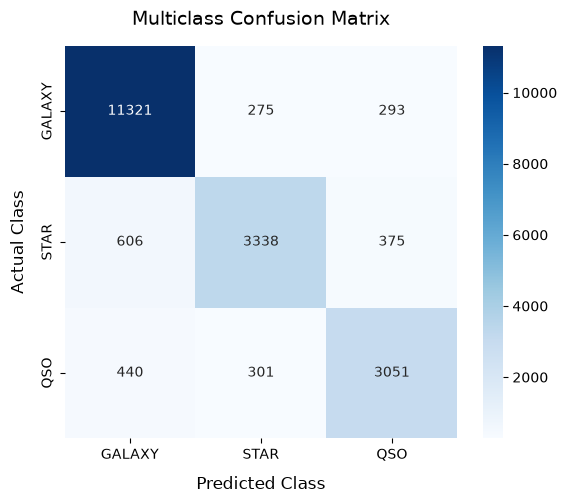

r_i   0.307
g_r    0.21
u_g   0.183
i_z   0.156
r     0.144
dtype: float64

In [78]:
# Final model: random forest on the 4 colors + r
# Trained on all training rows, scored once on the held-out test set.
final_features = colors + ['r']

final_model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
final_model.fit(df.loc[X_train.index, final_features], y_train)
final_preds = final_model.predict(df.loc[X_test.index, final_features])

print('===== final model: colors + r =====')
print(classification_report(y_test, final_preds, zero_division=0))
print(f"Test macro F1: {f1_score(y_test, final_preds, average='macro'):.3f}  (CV estimate: 0.854 ± 0.003)")

my_confusion_matrix(final_preds)

# Which features the forest relied on most
pd.Series(final_model.feature_importances_, index=final_features).sort_values(ascending=False).round(3)